# 10-手动控制T800机器人


## 1. 本课目标：用 MuJoCo GUI 试着控制机器人

本篇对应《具身智能机器人实战》第 10 节《手动控制 T800 机器人》，副标题为 `mujoco gui`。上一节给控制器设置了力矩范围，本节先不写自动控制器，而是借助 MuJoCo 的图形界面手动改变 T800 的关节状态，观察多个关节共同运动时的效果。

**资料依据：**[课程百度网盘资料](https://pan.baidu.com/s/1TI1Opoqy_jjmWCzhUOwliw?pwd=1234)，提取码 `1234`。已逐页核对 `ppt/10_手动控制T800机器人.pptx` 全部 3 页：第 1 页为主题，第 2 页提出手动控制 20 多个关节的两个问题，第 3 页为品牌结束页。

课件没有给出启动命令或按键清单，下面的 MuJoCo GUI 操作标为**工程补充**，依据 MuJoCo 3.4.0 的查看器文档和官方 `simulate.cc`。未转录配套视频，也未读取网盘中的 `code.zip`。


## 2. 为什么手动控制并不简单

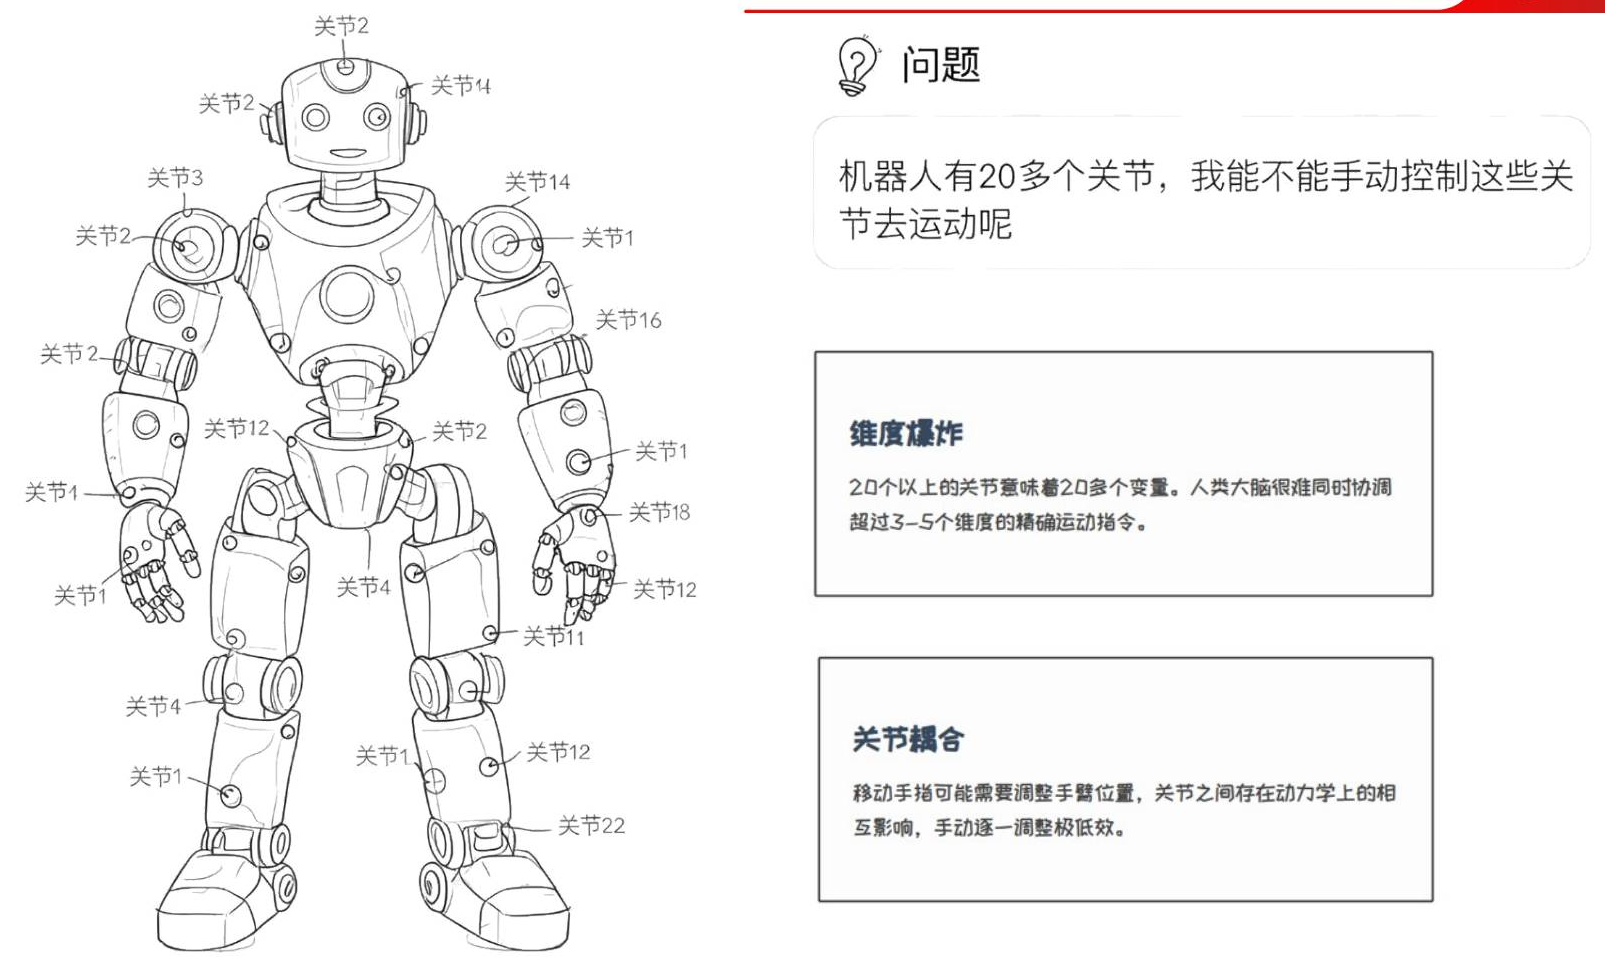

*原课件第 2 页：机器人有 20 多个关节，手动调整会遇到维度爆炸和关节耦合。*

课件提出的问题是：机器人有 20 多个关节，能不能手动控制这些关节运动？图中给出两个困难：

- **维度爆炸：**20 个以上的关节意味着 20 多个需要同时协调的变量。课件用“人类大脑很难同时协调超过 3～5 个维度的精确运动指令”说明手动协调的困难。
- **关节耦合：**课件举例，移动手指可能需要调整手臂位置；关节之间存在动力学上的相互影响，手动逐一调整的效率很低。一个末端动作往往需要多个关节共同配合。

因此，GUI 适合用来检查模型、试动单个关节和观察控制范围。能拖动一个滑块，并不意味着就能高效地协调全身关节。

**工程补充：**“3～5 个维度”是课件解释手动协调难度的说法，不作为人的固定生理上限。当前核对的官方 T800 模型提交为 `335c60e88772c26c7852d0abd6b3c7439037dd8f`，编译后有 26 个关节，其中 1 个是底座自由关节、25 个是转动关节，并配置了 25 个 motor。这个模型事实用于说明本地示例，不把课件中的插图编号当作 XML 关节名称。插图中的手指动作也是一般机器人举例，该版本 T800 没有单独配置手指 motor。


## 3. 工程补充：启动 MuJoCo GUI

沿用第 03 篇引入的官方 T800 模型和 `.venv`。在包含 `engineai_robotics_native_sdk` 的 `t800-load` 目录中，先把场景路径解析为绝对路径，再用 MuJoCo 自带查看器打开：

```powershell
$modelPath = (Resolve-Path '.\engineai_robotics_native_sdk\assets\resource\t800.xml').Path
.\.venv\Scripts\python.exe -m mujoco.viewer "--mjcf=$modelPath"
```

也可以把 `--mjcf` 的值直接替换为模型场景的完整绝对路径。本次 MuJoCo 3.4.0 环境在使用相对入口路径时出现嵌套 include 路径重复，改用绝对路径后加载成功。场景入口必须能找到 `robot/t800/xml/serial_t800.xml`、网格和纹理等相对资源；只拷贝一个 XML 文件可能导致 include 或资源加载失败。

MuJoCo 的 `viewer` 是交互式 GUI。`--mjcf` 方式由查看器自己推进仿真，适合本节的手动观察；如果从 Python 脚本调用 `launch_passive()`，则需要脚本自己循环调用 `mj_step()` 和 `viewer.sync()`，两种启动方式不要混为一谈。


## 4. 工程补充：用 Joint 和 Control 面板操作

### 4.1 先暂停，再调整 Joint 滑块

查看器右侧 UI 有 `Joint` 区域。对模型中的铰链关节，面板按关节名称生成滑块，滑块范围来自关节的 `range`；拖动滑块会直接修改对应的 `qpos`。当前 T800 使用弧度制，可以先按空格暂停，再展开右侧 `Joint`，找到 `J18_SHOULDER_PITCH_R` 并小幅拖动，观察右肩与手臂姿态。该关节范围为 `[-2.967, 2.793] rad`，不是第 09 篇的力矩范围。

建议按这个顺序操作：

1. 启动 GUI 后按 `F1` 查看当前版本的快捷键帮助。
2. 按空格在运行与暂停之间切换；暂停后再拖动 `Joint` 滑块，避免运动过程把手动改动立即带走。
3. 先只调整一个关节，观察它和相邻连杆的相对姿态，再尝试两个相关关节。
4. 需要回到初始状态时，在左侧 `Simulation` 区域使用 `Reset`；也可以关闭窗口后重新启动。

MuJoCo 的 `simulate` 源码把标量 hinge/slide 关节的滑块绑定到 `data.qpos[jnt_qposadr]`，所以此操作是直接修改仿真状态。它适合检查姿态和关节范围，不等同于电机真实运动过程。

### 4.2 Control 面板表示执行器输入

右侧 `Control` 区域为每个执行器生成控制滑块，范围来自该执行器的 `ctrlrange`。拖动 motor 的控制滑块，改变的是 `data.ctrl`，随后由动力学步进计算关节运动。对 `motor_J18_SHOULDER_PITCH_R`，本模型范围是 `[-160, 160]`；该 `gear=1` 的直接驱动 motor 可按 N·m 解释输入，不是目标角度。

先保持暂停，在 `Control` 中给一个 motor 设置小幅输入，再按 `Right` 前进一步观察状态变化。需要连续观察时再恢复运行，结束后用 `Control` 的 `Clear all` 清零输入。**清零输入不会自动把姿态恢复到初始状态**；恢复状态用 `Simulation` 的 `Reset`。

因此要区分：

| 面板 | 修改的量 | 适合观察 |
|---|---|---|
| `Joint` | 关节位置状态 `qpos` | 直接检查姿态、角度范围和连杆关系 |
| `Control` | 执行器控制输入 `ctrl` | 观察电机输入经过物理计算后的运动 |

两种操作的实验含义不同：直接改 `qpos` 可以瞬间改变姿态；拖动 `Control` 则需要物理步进，重力、摩擦、接触和其他关节都会影响结果。不要把拖动 Joint 得到的姿态当成电机已经完成了同一段运动。当前查看器没有自动接入第 08 篇的 PD 脚本，零输入也不代表保持站立；自由底座模型在恢复运行后可能下沉或倒下。

### 4.3 常用查看器快捷键

MuJoCo 3.4.0 的 `simulate` 提供这些与本课直接相关的快捷键：

| 按键 | 作用 |
|---|---|
| `Space` | 播放 / 暂停 |
| `Left`、`Right` | 回看已记录的状态 / 暂停时向前一步；回看历史时先沿历史前进 |
| `Tab`、`Shift+Tab` | 切换左、右侧 UI |
| `F1` | 打开帮助 |
| `Esc` | 切换自由相机 |
| `Backspace` | 重置仿真 |

快捷键以当前 MuJoCo 版本窗口中的帮助为准；本表整理自同版本官方查看器源码。窗口焦点在滑块或文本框时，先点击 3D 视图再按快捷键。


## 5. 本课检查与补充参考

完成本节，应能解释 20 多个关节为什么带来维度爆炸，说明关节耦合为什么让逐个拖动低效，并区分 `Joint` 直接改姿态与 `Control` 施加执行器输入的区别。

本篇已核对 `--mjcf` 命令入口，并通过同一查看器的模型加载函数，用绝对路径加载官方 T800 场景。模型为 26 个关节、32 个位置坐标、31 个速度自由度和 25 个执行器；默认分组显示时，25 个铰链关节对应标量 `Joint` 滑块，自由底座不按同样方式列出。已对照同版本源码确认面板绑定和快捷键，没有打开 GUI 做鼠标交互实测，也没有验证站立、全身协调或真实硬件控制。

- [MuJoCo 3.4.0：Python 交互式查看器](https://mujoco.readthedocs.io/en/3.4.0/python.html#interactive-viewer)。
- [MuJoCo 3.4.0：被动查看器](https://mujoco.readthedocs.io/en/3.4.0/python.html#passive-viewer)。
- [MuJoCo 3.4.0：用户界面](https://mujoco.readthedocs.io/en/3.4.0/programming/ui.html)。
- [同版本官方 `simulate.cc` 的 Joint/Control 面板实现](https://github.com/google-deepmind/mujoco/blob/3.4.0/simulate/simulate.cc)。
- [本篇版本的 T800 场景文件](https://github.com/engineai-robotics/engineai_robotics_native_sdk/blob/335c60e88772c26c7852d0abd6b3c7439037dd8f/assets/resource/t800.xml)。
